In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

file_path = Path("../Online Retail.xlsx")

if not file_path.exists():
    file_path = Path("Online Retail.xlsx")

df = pd.read_excel(file_path)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


سوال 1 : دیتاست چند رکورد و چند ستون دارد؟
دیتاست Online Retail در نسخه اصلی شامل 541,909 رکورد و 8 ستون است. هر رکورد نشان‌دهنده اطلاعات مربوط به یک ردیف از تراکنش‌های فروشگاه آنلاین است و ستون‌ها اطلاعاتی مانند شماره فاکتور، کد محصول، تعداد کالا، قیمت واحد، تاریخ خرید و شناسه مشتری را در بر می‌گیرند.

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 541909
Number of columns: 8
Dataset shape: (541909, 8)


<div dir="rtl" align="right">

### پاسخ سؤال ۲: واحد هر رکورد چیست و ستون‌ها چه اطلاعاتی ارائه می‌کنند؟

**واحد هر رکورد:** هر رکورد نشان‌دهنده اطلاعات مربوط به یک محصول در یک سفارش ثبت‌شده در فروشگاه آنلاین است.

**معرفی ستون‌های دیتاست:**

| نام ستون | اطلاعات ارائه‌شده |
|---|---|
| `InvoiceNo` | شماره فاکتور و شناسایی سفارش |
| `StockCode` | کد شناسایی محصول |
| `Description` | نام و مشخصات محصول |
| `Quantity` | تعداد کالاهای خریداری‌شده |
| `InvoiceDate` | تاریخ ثبت خرید |
| `UnitPrice` | قیمت واحد محصول |
| `CustomerID` | شناسه مشتری |
| `Country` | کشور مشتری |

**جمع‌بندی:** این ستون‌ها اطلاعات مربوط به مشتریان، سفارش‌ها، محصولات، تعداد کالاهای خریداری‌شده، قیمت و زمان خرید را در اختیار ما قرار می‌دهند و مبنای تحلیل رفتار خرید مشتریان هستند.

</div>

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nSample records:")
print(df.head())

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Sample records:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39    

## سؤال ۳: تعداد موجودیت‌های یکتا در دیتاست چقدر است؟

| نوع موجودیت | تعداد مقادیر یکتا |
|---|---:|
| مشتریان (CustomerID) | 4,372 |
| فاکتورها (InvoiceNo) | 25,900 |
| محصولات (StockCode) | 4,070 |
| توضیحات محصولات (Description) | 4,223 |
| کشورها (Country) | 38 |

دیتاست Online Retail شامل موجودیت‌های مختلفی است. بر اساس بررسی داده‌ها، تعداد مشتریان یکتا برابر با 4,372، تعداد فاکتورهای یکتا برابر با 25,900، تعداد محصولات یکتا برابر با 4,070 و تعداد کشورهای موجود در دیتاست برابر با 38 کشور است.

In [ ]:
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique customers:", df["CustomerID"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique countries:", df["Country"].nunique())

Unique invoices: 25900
Unique customers: 4372
Unique products: 4070
Unique countries: 38


## سؤال ۴: تعداد و درصد داده‌های گمشده در هر ستون چقدر است؟

بررسی داده‌های گمشده نشان می‌دهد که از مجموع 541,909 رکورد، ستون **CustomerID** دارای بیشترین تعداد داده گمشده با 135,080 مقدار (24.93 درصد) است. همچنین ستون **Description** دارای 1,454 مقدار گمشده (0.27 درصد) است. شش ستون دیگر هیچ مقدار گمشده‌ای ندارند.

**نکته:** در مجموع 136,534 مقدار گمشده در کل دیتاست وجود دارد.

             Missing_Count  Missing_Percent
CustomerID          135080        24.926694
Description           1454         0.268311
StockCode                0         0.000000
InvoiceNo                0         0.000000
Quantity                 0         0.000000
InvoiceDate              0         0.000000
UnitPrice                0         0.000000
Country                  0         0.000000


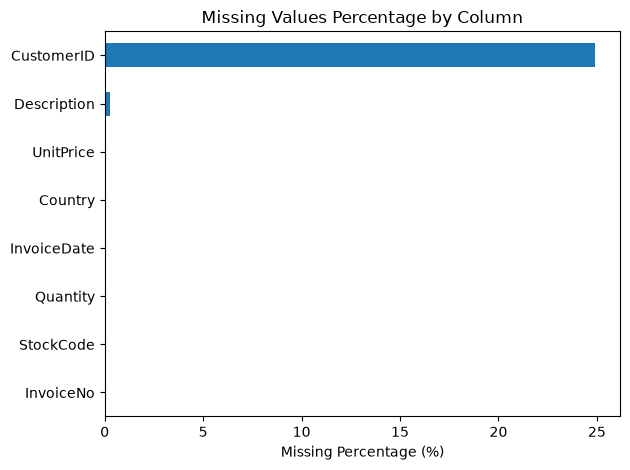

In [ ]:
missing_count = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

print(missing_report.sort_values(
    by="Missing_Percent",
    ascending=False
))

missing_report["Missing_Percent"].sort_values().plot(
    kind="barh",
    title="Missing Values Percentage by Column",
    xlabel="Missing Percentage (%)"
)

plt.tight_layout()
plt.show()

## سؤال ۵: چند ردیف کاملاً تکراری در دیتاست وجود دارد؟

1. تعداد کل رکوردها: 541,909
2. تعداد ردیف‌های تکراری: 5,268
3. درصد ردیف‌های تکراری: 0.97٪

بررسی داده‌ها نشان می‌دهد که از مجموع 541,909 رکورد موجود در دیتاست، تعداد 5,268 ردیف کاملاً تکراری هستند. این تعداد معادل حدود 0.97 درصد از کل رکوردها است.

In [ ]:
duplicate_count = df.duplicated().sum()
duplicate_percent = df.duplicated().mean() * 100

print("Duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percent, 2), "%")

print("\nExamples of duplicate rows:")
print(df[df.duplicated(keep=False)].head(10))

Duplicate rows: 5268
Duplicate percentage: 0.97 %

Examples of duplicate rows:
    InvoiceNo StockCode                        Description  Quantity  \
485    536409     22111       SCOTTIE DOG HOT WATER BOTTLE         1   
489    536409     22866      HAND WARMER SCOTTY DOG DESIGN         1   
494    536409     21866        UNION JACK FLAG LUGGAGE TAG         1   
517    536409     21866        UNION JACK FLAG LUGGAGE TAG         1   
521    536409     22900    SET 2 TEA TOWELS I LOVE LONDON          1   
527    536409     22866      HAND WARMER SCOTTY DOG DESIGN         1   
537    536409     22900    SET 2 TEA TOWELS I LOVE LONDON          1   
539    536409     22111       SCOTTIE DOG HOT WATER BOTTLE         1   
548    536412     22327  ROUND SNACK BOXES SET OF 4 SKULLS         1   
555    536412     22327  ROUND SNACK BOXES SET OF 4 SKULLS         1   

            InvoiceDate  UnitPrice  CustomerID         Country  
485 2010-12-01 11:45:00       4.95     17908.0  United Kingdom 

## سؤال ۶: بازه زمانی دیتاست چیست و فعالیت ثبت‌شده در طول ماه‌ها چگونه تغییر می‌کند؟

بازه زمانی دیتاست از اول دسامبر ۲۰۱۰ تا ۹ دسامبر ۲۰۱۱ است. بررسی تعداد رکوردهای ثبت‌شده در ماه‌های مختلف نشان می‌دهد که میزان فعالیت در طول زمان نوسان داشته است. بیشترین فعالیت مربوط به نوامبر ۲۰۱۱ با 84,711 رکورد و کمترین فعالیت در میان ماه‌های کامل مربوط به فوریه ۲۰۱۱ با 27,707 رکورد است. همچنین از سپتامبر ۲۰۱۱ روند افزایشی قابل‌توجهی در تعداد رکوردها مشاهده می‌شود.

**نکته:** ماه دسامبر ۲۰۱۱ به‌صورت ناقص در دیتاست ثبت شده و فقط ۹ روز اول آن را شامل می‌شود.

Invalid dates: 0
Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00

Monthly Summary:
         Row_Count  Unique_Invoices  Unique_Customers
Month                                                
2010-12      42481             2025               948
2011-01      35147             1476               783
2011-02      27707             1393               798
2011-03      36748             1983              1020
2011-04      29916             1744               899
2011-05      37030             2162              1079
2011-06      36874             2012              1051
2011-07      39518             1927               993
2011-08      35284             1737               980
2011-09      50226             2327              1302
2011-10      60742             2637              1425
2011-11      84711             3462              1711
2011-12      25525             1015               686


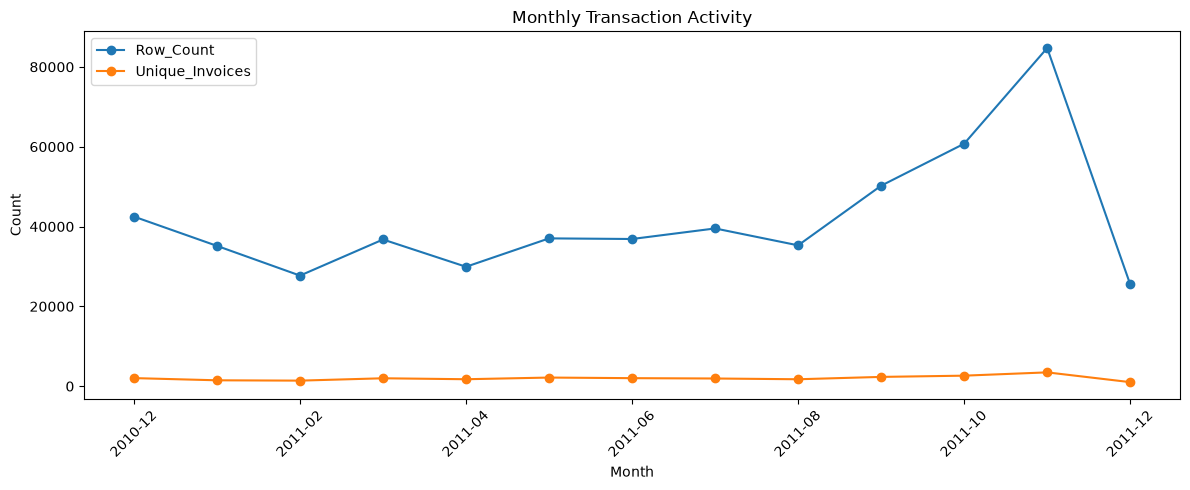

In [ ]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

print("Invalid dates:", df["InvoiceDate"].isna().sum())
print("Earliest date:", df["InvoiceDate"].min())
print("Latest date:", df["InvoiceDate"].max())

monthly_summary = (
    df.dropna(subset=["InvoiceDate"])
    .assign(
        Month=df["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month")
    .agg(
        Row_Count=("InvoiceNo", "size"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
)

print("\nMonthly Summary:")
print(monthly_summary)

monthly_summary[["Row_Count", "Unique_Invoices"]].plot(
    figsize=(12, 5),
    marker="o",
    title="Monthly Transaction Activity"
)

plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## سؤال ۷: چه تعداد رکورد و فاکتور با نشانه لغو ثبت شده‌اند؟

بررسی ستون InvoiceNo نشان می‌دهد که در این دیتاست، فاکتورهای لغوشده با حرف C در ابتدای شماره فاکتور مشخص شده‌اند. بر این اساس، تعداد 9,288 رکورد مربوط به فاکتورهای لغوشده است که در مجموع شامل 3,836 فاکتور یکتا می‌شود. این رکوردها حدود 1.71 درصد از کل داده‌های دیتاست را تشکیل می‌دهند.

In [ ]:
cancelled_mask = (
    df["InvoiceNo"]
    .astype("string")
    .str.startswith("C", na=False)
)

print("Rows with cancellation prefix:", cancelled_mask.sum())

print(
    "Percentage of rows:",
    round(cancelled_mask.mean() * 100, 2),
    "%"
)

print(
    "Unique cancellation invoice numbers:",
    df.loc[cancelled_mask, "InvoiceNo"].nunique()
)

print("\nExamples:")
print(df.loc[cancelled_mask].head(10))

Rows with cancellation prefix: 9288
Percentage of rows: 1.71 %
Unique cancellation invoice numbers: 3836

Examples:
    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960           JAM MAKING SET WITH JARS        -6   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00   

## سؤال ۸: آیا در تعداد کالا و قیمت واحد، مقادیر منفی یا صفر وجود دارد؟

بررسی ستون‌های Quantity و UnitPrice نشان می‌دهد که در هر دو ستون مقادیر منفی یا صفر وجود دارد. در ستون Quantity تعداد 10,624 مقدار منفی مشاهده شده است، در حالی که هیچ مقدار صفری وجود ندارد. همچنین در ستون UnitPrice تعداد 2 مقدار منفی و 2,515 مقدار صفر ثبت شده است. مقادیر منفی در تعداد کالا می‌توانند نشان‌دهنده مرجوعی کالا باشند و مقادیر صفر یا منفی در قیمت واحد نیازمند بررسی بیشتر هستند.

In [ ]:
for column in ["Quantity", "UnitPrice"]:
    print(f"\nColumn: {column}")
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())
    print("Negative values:", (df[column] < 0).sum())
    print("Zero values:", (df[column] == 0).sum())
    print("Positive values:", (df[column] > 0).sum())

print("\nRows with negative Quantity:")
print(df[df["Quantity"] < 0].head(10))

print("\nRows with non-positive UnitPrice:")
print(df[df["UnitPrice"] <= 0].head(10))



Column: Quantity
Minimum: -80995
Maximum: 80995
Negative values: 10624
Zero values: 0
Positive values: 531285

Column: UnitPrice
Minimum: -11062.06
Maximum: 38970.0
Negative values: 2
Zero values: 2515
Positive values: 539392

Rows with negative Quantity:
    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960

## سؤال ۹: توزیع Quantity و UnitPrice چگونه است و چه مقادیر افراطی‌ای دیده می‌شود؟

### ۱. آمار توصیفی Quantity و UnitPrice

| شاخص آماری | Quantity | UnitPrice |
|---|---:|---:|
| میانگین (Mean) | 9.55 | 4.61 |
| میانه (Median) | 3 | 2.08 |
| انحراف معیار (Std) | 218.08 | 96.76 |
| حداقل (Min) | -80,995 | -11,062.06 |
| چارک اول (Q1) | 1 | 1.25 |
| چارک سوم (Q3) | 10 | 4.13 |
| صدک ۹۵ | 29 | 9.95 |
| صدک ۹۹ | 100 | 18 |
| حداکثر (Max) | 80,995 | 38,970 |

### ۲. تحلیل توزیع و مقادیر افراطی

**ستون Quantity:**

- بیشتر مقادیر تعداد کالا در محدوده پایین قرار دارند.
- میانه برابر با 3 است؛ یعنی نیمی از رکوردها تعداد کالای 3 یا کمتر دارند.
- مقادیر بسیار بزرگی مانند 80,995 و مقادیر منفی مانند 80,995- مشاهده می‌شوند.
- اختلاف زیاد میان میانگین (9.55) و میانه (3) نشان‌دهنده تأثیر مقادیر افراطی بر میانگین است.

**ستون UnitPrice:**

- بیشتر قیمت‌ها در محدوده پایین قرار دارند.
- میانه قیمت واحد 2.08 است.
- قیمت‌های بسیار بزرگی مانند 38,970 و قیمت منفی 11,062.06- مشاهده می‌شوند.
- اختلاف زیاد میانگین (4.61) و میانه (2.08) نشان‌دهنده تأثیر شدید مقادیر افراطی بر توزیع قیمت است.

### ۳. شناسایی مقادیر پرت با روش IQR

با استفاده از روش فاصله بین چارکی (IQR)، مقادیر پرت به شکل زیر شناسایی می‌شوند:

| ستون | تعداد مقادیر پرت |
|---|---:|
| Quantity | 58,619 |
| UnitPrice | 39,627 |

بررسی توزیع متغیرهای Quantity و UnitPrice نشان می‌دهد که بیشتر مقادیر این دو ستون در محدوده‌های پایین قرار دارند و تعداد محدودی از رکوردها دارای مقادیر بسیار بزرگ یا منفی هستند. در ستون Quantity، مقدار حداکثر 80,995 و حداقل 80,995- است. همچنین در ستون UnitPrice، مقدار حداکثر 38,970 و حداقل 11,062.06- مشاهده می‌شود. اختلاف قابل‌توجه میان میانگین و میانه در هر دو متغیر نشان‌دهنده تأثیر مقادیر افراطی بر توزیع داده‌ها است. با استفاده از روش IQR نیز تعداد 58,619 مقدار پرت در ستون Quantity و 39,627 مقدار پرت در ستون UnitPrice شناسایی شده است. بنابراین، این دو متغیر دارای مقادیر پرت قابل‌توجهی هستند که در مرحله آماده‌سازی داده‌ها باید مورد بررسی قرار گیرند.

            Quantity      UnitPrice
count  541909.000000  541909.000000
mean        9.552250       4.611114
std       218.081158      96.759853
min    -80995.000000  -11062.060000
25%         1.000000       1.250000
50%         3.000000       2.080000
75%        10.000000       4.130000
max     80995.000000   38970.000000

Selected percentiles:
       Quantity  UnitPrice
0.500      3.00     2.0800
0.750     10.00     4.1300
0.900     24.00     7.9500
0.950     29.00     9.9500
0.990    100.00    18.0000
0.999    468.92   205.5598


NameError: name 'sns' is not defined

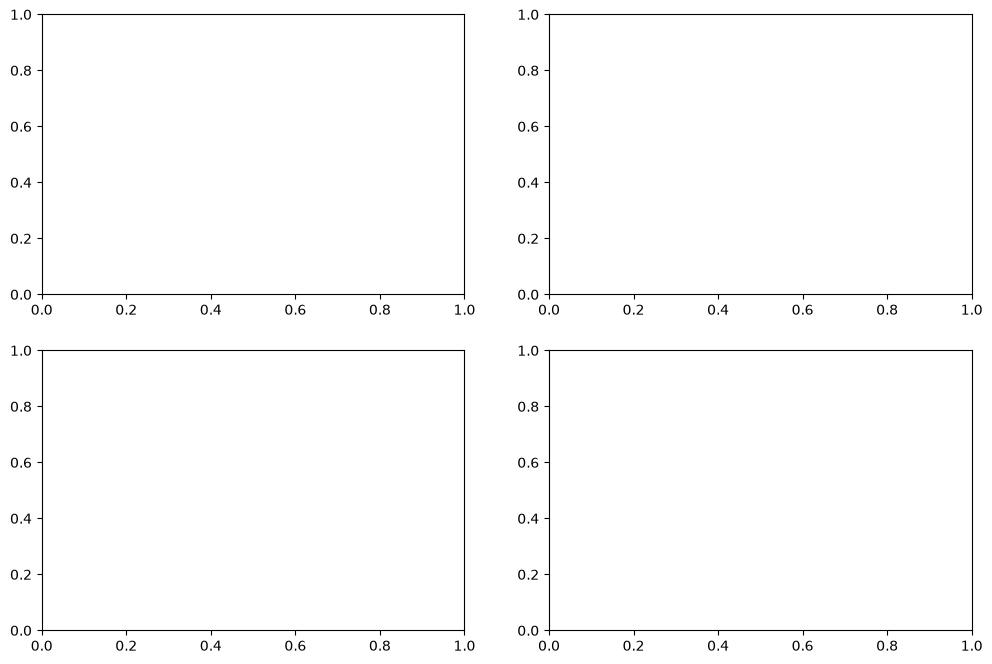

In [ ]:
print(df[["Quantity", "UnitPrice"]].describe())

print("\nSelected percentiles:")
print(
    df[["Quantity", "UnitPrice"]].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    )
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["Quantity"], bins=100, ax=axes[0, 0])
axes[0, 0].set_title("Quantity Distribution")

sns.boxplot(x=df["Quantity"], ax=axes[0, 1])
axes[0, 1].set_title("Quantity Boxplot")

sns.histplot(df["UnitPrice"], bins=100, ax=axes[1, 0])
axes[1, 0].set_title("UnitPrice Distribution")

sns.boxplot(x=df["UnitPrice"], ax=axes[1, 1])
axes[1, 1].set_title("UnitPrice Boxplot")

plt.tight_layout()
plt.show()

## سؤال ۱۰: کدام کشورها بیشترین سهم از رکوردها و مشتریان را دارند؟

### ۱. کشورهای دارای بیشترین تعداد رکورد

| کشور | تعداد رکورد | درصد از کل رکوردها |
|---|---:|---:|
| United Kingdom | 495,478 | 91.43٪ |
| Germany | 9,495 | 1.75٪ |
| France | 8,557 | 1.58٪ |
| EIRE | 8,196 | 1.51٪ |
| Spain | 2,533 | 0.47٪ |
| Netherlands | 2,371 | 0.44٪ |
| Belgium | 2,069 | 0.38٪ |
| Switzerland | 2,002 | 0.37٪ |
| Portugal | 1,519 | 0.28٪ |
| Australia | 1,259 | 0.23٪ |

### ۲. کشورهای دارای بیشترین تعداد مشتری

| کشور | تعداد مشتری یکتا |
|---|---:|
| United Kingdom | 3,950 |
| Germany | 95 |
| France | 87 |
| Spain | 31 |
| Belgium | 25 |
| Switzerland | 21 |
| Portugal | 19 |
| Italy | 15 |
| Finland | 12 |
| Austria | 11 |

### ۳. تحلیل نتایج

- بریتانیا با 495,478 رکورد، حدود 91.43 درصد کل رکوردهای دیتاست را به خود اختصاص داده است.
- آلمان و فرانسه به‌ترتیب در رتبه‌های دوم و سوم از نظر تعداد رکورد قرار دارند.
- بریتانیا با 3,950 مشتری یکتا، بیشترین تعداد مشتری را نیز دارد.
- تمرکز بسیار زیاد رکوردها و مشتریان در بریتانیا نشان می‌دهد که بازار اصلی فروشگاه در این کشور قرار داشته است.

بررسی توزیع جغرافیایی داده‌ها نشان می‌دهد که کشور United Kingdom (بریتانیا) بیشترین سهم را از تعداد رکوردها و مشتریان دارد. این کشور با 495,478 رکورد، معادل 91.43 درصد کل داده‌ها را به خود اختصاص داده و دارای 3,950 مشتری یکتا است. پس از آن کشورهای آلمان و فرانسه از نظر تعداد رکورد در رتبه‌های دوم و سوم قرار دارند. این نتایج نشان می‌دهد که فعالیت اصلی فروشگاه آنلاین در بازار بریتانیا متمرکز بوده است.

Top countries by number of rows:
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

Top countries by unique customers:
Country
United Kingdom    3950
Germany             95
France              87
Spain               31
Belgium             25
Switzerland         21
Portugal            19
Italy               15
Finland             12
Austria             11
Name: CustomerID, dtype: int64

United Kingdom row percentage: 91.43 %


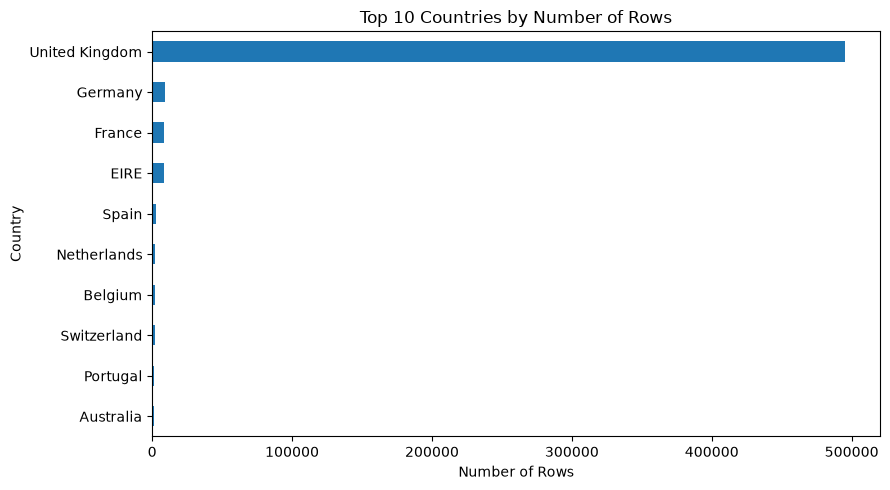

In [ ]:
country_rows = df["Country"].value_counts()

country_customers = (
    df.groupby("Country")["CustomerID"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top countries by number of rows:")
print(country_rows.head(10))

print("\nTop countries by unique customers:")
print(country_customers.head(10))

print(
    "\nUnited Kingdom row percentage:",
    round(
        (df["Country"] == "United Kingdom").mean() * 100,
        2
    ),
    "%"
)

country_rows.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top 10 Countries by Number of Rows",
    xlabel="Number of Rows"
)

plt.tight_layout()
plt.show()

## سؤال ۱۱: پرتکرارترین محصولات از نظر تعداد ردیف‌های ثبت‌شده کدام‌اند؟

برای پاسخ به این سؤال، تعداد دفعات ثبت هر محصول در دیتاست را بر اساس کد محصول (StockCode) محاسبه می‌کنیم. منظور از پرتکرارترین محصول، محصولی است که در بیشترین تعداد ردیف‌های دیتاست ثبت شده باشد؛ نه لزوماً محصولی که بیشترین تعداد فروش را داشته است.

### ۱. ده محصول پرتکرار دیتاست

| کد محصول | نام محصول | تعداد ردیف ثبت‌شده |
|---|---|---:|
| 85123A | WHITE HANGING HEART T-LIGHT HOLDER | 2,313 |
| 22423 | REGENCY CAKESTAND 3 TIER | 2,203 |
| 85099B | JUMBO BAG RED RETROSPOT | 2,159 |
| 47566 | PARTY BUNTING | 1,727 |
| 20725 | LUNCH BAG RED RETROSPOT | 1,639 |
| 84879 | ASSORTED COLOUR BIRD ORNAMENT | 1,502 |
| 22720 | SET OF 3 CAKE TINS PANTRY DESIGN | 1,477 |
| 22197 | POPCORN HOLDER | 1,476 |
| 21212 | PACK OF 72 RETROSPOT CAKE CASES | 1,385 |
| 20727 | LUNCH BAG BLACK SKULL | 1,350 |

### ۲. تحلیل نتایج

- پرتکرارترین محصول، WHITE HANGING HEART T-LIGHT HOLDER با 2,313 ردیف ثبت‌شده است.
- محصول REGENCY CAKESTAND 3 TIER با 2,203 ردیف در رتبه دوم قرار دارد.
- محصول JUMBO BAG RED RETROSPOT با 2,159 ردیف رتبه سوم را به خود اختصاص داده است.
- این نتایج نشان می‌دهد که محصولات تزئینی، لوازم آشپزخانه و کیف‌های خرید از جمله محصولات پرتکرار در تراکنش‌های فروشگاه هستند.

بررسی فراوانی محصولات بر اساس کد StockCode نشان می‌دهد که محصول WHITE HANGING HEART T-LIGHT HOLDER با 2,313 ردیف ثبت‌شده، پرتکرارترین محصول دیتاست است. پس از آن محصولات REGENCY CAKESTAND 3 TIER با 2,203 ردیف و JUMBO BAG RED RETROSPOT با 2,159 ردیف در رتبه‌های دوم و سوم قرار دارند. این بررسی نشان می‌دهد که برخی محصولات تزئینی و لوازم خانگی از بیشترین فراوانی در تراکنش‌های فروشگاه برخوردار هستند.

           Row_Count                         Description
StockCode                                               
85123A          2313  WHITE HANGING HEART T-LIGHT HOLDER
22423           2203            REGENCY CAKESTAND 3 TIER
85099B          2159             JUMBO BAG RED RETROSPOT
47566           1727                       PARTY BUNTING
20725           1639             LUNCH BAG RED RETROSPOT
84879           1502       ASSORTED COLOUR BIRD ORNAMENT
22720           1477   SET OF 3 CAKE TINS PANTRY DESIGN 
22197           1476                SMALL POPCORN HOLDER
21212           1385     PACK OF 72 RETROSPOT CAKE CASES
20727           1350             LUNCH BAG  BLACK SKULL.


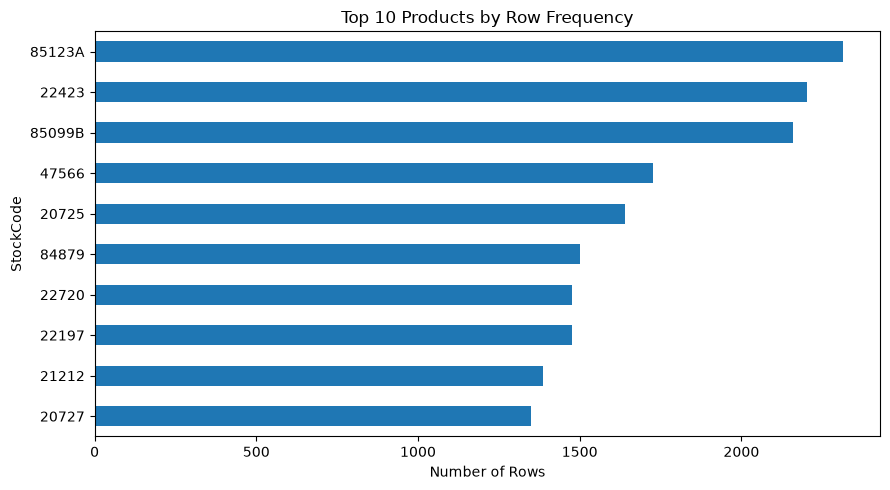

In [ ]:
top_products = df["StockCode"].value_counts().head(10)

product_names = (
    df.groupby("StockCode")["Description"]
    .first()
)

top_product_report = pd.DataFrame({
    "Row_Count": top_products,
    "Description": product_names.reindex(top_products.index)
})

print(top_product_report)

top_products.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top 10 Products by Row Frequency",
    xlabel="Number of Rows"
)

plt.tight_layout()
plt.show()

## سؤال ۱۲: هر فاکتور به‌طور معمول چند ردیف کالایی دارد؟

### ۱. آمار تعداد ردیف‌های هر فاکتور

با در نظر گرفتن تمام فاکتورها، حتی فاکتورهای لغوشده:

| شاخص آماری | تعداد ردیف |
|---|---:|
| تعداد کل فاکتورها | 25,900 |
| میانگین (Mean) | 20.92 |
| میانه (Median) | 10 |
| حداقل (Min) | 1 |
| چارک اول (Q1) | 2 |
| چارک سوم (Q3) | 23 |
| صدک ۹۰ | 47 |
| حداکثر (Max) | 1,114 |

### ۲. تحلیل نتایج

- هر فاکتور به‌طور میانگین شامل حدود 21 ردیف کالایی است.
- میانه برابر با 10 است؛ یعنی نیمی از فاکتورها حداکثر 10 ردیف کالایی دارند.
- پرتکرارترین تعداد ردیف برای یک فاکتور، یک ردیف است.
- بیشترین تعداد ردیف ثبت‌شده برای یک فاکتور برابر با 1,114 است.
- اختلاف میانگین و میانه نشان می‌دهد که تعداد کمی از فاکتورها دارای ردیف‌های بسیار زیادی هستند و میانگین را افزایش داده‌اند.
- بررسی تعداد ردیف‌های کالایی در هر فاکتور نشان می‌دهد که دیتاست شامل 25,900 فاکتور است. هر فاکتور به‌طور میانگین دارای 20.92 ردیف کالایی است، در حالی که مقدار میانه برابر با 10 ردیف است. این اختلاف نشان می‌دهد که تعداد محدودی از فاکتورها دارای تعداد ردیف‌های بسیار زیادی هستند. همچنین بیشترین تعداد ردیف ثبت‌شده برای یک فاکتور برابر با 1,114 است. به‌طور کلی، بیشتر فاکتورها تعداد ردیف کالایی نسبتاً کمی دارند.

Unique invoices: 25900

Rows per invoice statistics:
count    25900.000000
mean        20.923127
std         43.031334
min          1.000000
25%          2.000000
50%         10.000000
75%         23.000000
max       1114.000000
dtype: float64

Median rows per invoice: 10.0
Maximum rows per invoice: 1114


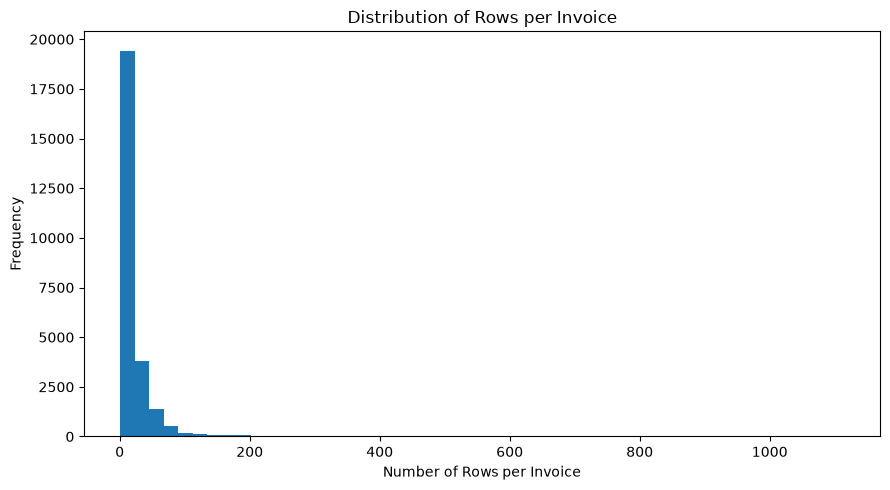

In [ ]:
invoice_row_counts = df.groupby("InvoiceNo").size()

print("Unique invoices:", invoice_row_counts.size)
print("\nRows per invoice statistics:")
print(invoice_row_counts.describe())

print(
    "\nMedian rows per invoice:",
    invoice_row_counts.median()
)

print(
    "Maximum rows per invoice:",
    invoice_row_counts.max()
)

invoice_row_counts.plot(
    kind="hist",
    bins=50,
    figsize=(9, 5),
    title="Distribution of Rows per Invoice",
    xlabel="Number of Rows per Invoice"
)

plt.tight_layout()
plt.show()

## سؤال ۱۳: مشتریان در چند فاکتور یکتا حضور دارند و توزیع تعداد فاکتورهای آن‌ها چگونه است؟

### ۱. آمار تعداد فاکتورهای هر مشتری

در این محاسبه، فقط ردیف‌هایی در نظر گرفته شده‌اند که `CustomerID` دارند. همچنین فاکتورهای لغوشده نیز در محاسبه لحاظ شده‌اند.

| شاخص آماری | مقدار |
|---|---:|
| تعداد مشتریان یکتا | 4,372 |
| مجموع فاکتورهای یکتای مشتریان | 22,190 |
| میانگین تعداد فاکتور برای هر مشتری | 5.08 |
| میانه (Median) | 3 |
| حداقل (Min) | 1 |
| چارک اول (Q1) | 1 |
| چارک سوم (Q3) | 5 |
| صدک ۹۰ | 11 |
| صدک ۹۵ | 16 |
| صدک ۹۹ | 36 |
| حداکثر (Max) | 248 |

### ۲. توزیع تعداد فاکتورها بین مشتریان

برای درک بهتر رفتار خرید مشتریان، تعداد فاکتورهای آن‌ها را در چند گروه تقسیم می‌کنیم:

| تعداد فاکتور برای هر مشتری | تعداد مشتریان | درصد مشتریان |
|---|---:|---:|
| 1 فاکتور | 1,313 | 30.03٪ |
| 2 تا 5 فاکتور | 1,972 | 45.11٪ |
| 6 تا 10 فاکتور | 628 | 14.36٪ |
| 11 تا 20 فاکتور | 317 | 7.25٪ |
| 21 تا 50 فاکتور | 118 | 2.70٪ |
| 51 تا 100 فاکتور | 18 | 0.41٪ |
| 101 تا 300 فاکتور | 6 | 0.14٪ |

### ۳. تحلیل نتایج

- دیتاست شامل 4,372 مشتری با شناسه مشخص است.
- هر مشتری به‌طور میانگین در حدود 5.08 فاکتور حضور دارد.
- میانه برابر با 3 است؛ یعنی نیمی از مشتریان حداکثر 3 فاکتور دارند.
- حدود 30 درصد مشتریان فقط در یک فاکتور حضور داشته‌اند.
- بیشترین تعداد مشتریان، یعنی 45.11 درصد، بین 2 تا 5 فاکتور دارند.
- تنها تعداد کمی از مشتریان بیش از 20 فاکتور ثبت کرده‌اند.
- بیشترین تعداد فاکتور متعلق به یک مشتری برابر با 248 فاکتور است.
- اختلاف میانگین و میانه نشان می‌دهد که تعداد محدودی از مشتریان خریدهای مکرر و زیادی داشته‌اند و میانگین را افزایش داده‌اند.
- بررسی تعداد فاکتورهای یکتای هر مشتری نشان می‌دهد که از مجموع مشتریان دارای شناسه مشخص، 4,372 مشتری در دیتاست وجود دارد. هر مشتری به‌طور میانگین در 5.08 فاکتور حضور داشته است، در حالی که مقدار میانه برابر با 3 فاکتور است. همچنین حدود 30 درصد مشتریان تنها یک فاکتور دارند و بیشترین سهم مشتریان، معادل 45.11 درصد، بین 2 تا 5 فاکتور ثبت کرده‌اند. بیشترین تعداد فاکتور متعلق به یک مشتری برابر با 248 است. این نتایج نشان می‌دهد که بخش قابل‌توجهی از مشتریان تعداد خرید محدودی دارند، در حالی که گروه کوچکی از مشتریان رفتار خرید مکرر و وفاداری بیشتری نشان می‌دهند.

**نکته تحلیلی:** اگر فاکتورهای لغوشده را از محاسبات حذف کنیم، تعداد مشتریان دارای حداقل یک فاکتور معتبر به 4,339 نفر و میانگین تعداد فاکتورهای هر مشتری به 4.27 کاهش می‌یابد. برای تحلیل رفتار خرید واقعی مشتریان، معمولاً بررسی جداگانه فاکتورهای لغوشده و معتبر مفیدتر است.

Unique customers: 4372

Invoices per customer statistics:
count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64

Median invoices per customer: 3.0
Maximum invoices per customer: 248


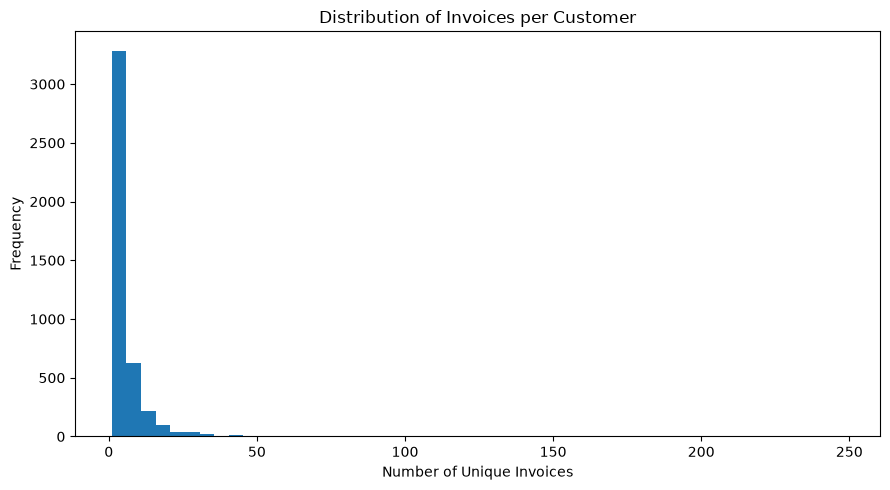

In [ ]:
customer_invoice_counts = (
    df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

print("Unique customers:", customer_invoice_counts.size)

print("\nInvoices per customer statistics:")
print(customer_invoice_counts.describe())

print(
    "\nMedian invoices per customer:",
    customer_invoice_counts.median()
)

print(
    "Maximum invoices per customer:",
    customer_invoice_counts.max()
)

customer_invoice_counts.plot(
    kind="hist",
    bins=50,
    figsize=(9, 5),
    title="Distribution of Invoices per Customer",
    xlabel="Number of Unique Invoices"
)

plt.tight_layout()
plt.show()

## سؤال ۱۴: آیا دیتاست از قبل دارای برچسب Churn است؟

خیر. دیتاست Online Retail به‌صورت پیش‌فرض دارای ستون یا برچسب مشخصی برای `Churn` نیست.

با بررسی ساختار دیتاست، ستون‌های زیر وجود دارند:

| نام ستون | توضیحات |
|---|---|
| `InvoiceNo` | شماره فاکتور |
| `StockCode` | کد کالا |
| `Description` | توضیحات کالا |
| `Quantity` | تعداد کالای خریداری‌شده |
| `InvoiceDate` | تاریخ و زمان ثبت فاکتور |
| `UnitPrice` | قیمت واحد کالا |
| `CustomerID` | شناسه مشتری |
| `Country` | کشور مشتری |

همان‌طور که مشاهده می‌شود، هیچ‌کدام از این ستون‌ها نشان نمی‌دهند که یک مشتری ریزش کرده است یا خیر.

### ۱. چرا برچسب Churn وجود ندارد؟

این دیتاست صرفاً سوابق تراکنش‌ها و خرید مشتریان را ثبت می‌کند. بنابراین اطلاعات مستقیمی درباره موارد زیر ندارد:

- مشتریانی که دیگر خریدی انجام نمی‌دهند.
- مشتریانی که ارتباط خود را با فروشگاه قطع کرده‌اند.
- مشتریانی که همچنان فعال هستند یا از دست رفته‌اند.

### ۲. چگونه می‌توان برچسب Churn ایجاد کرد؟

برای انجام پروژه پیش‌بینی ریزش مشتری، باید برچسب `Churn` را با استفاده از رفتار خرید مشتریان ایجاد کنیم.

یک روش رایج، استفاده از مدت‌زمان عدم خرید مشتری است. برای مثال:

- اگر مشتری در ۹۰ روز اخیر خریدی انجام نداده باشد، `Churn = 1` در نظر گرفته می‌شود.
- اگر مشتری در ۹۰ روز اخیر حداقل یک خرید داشته باشد، `Churn = 0` در نظر گرفته می‌شود.

البته آستانه ۹۰ روز صرفاً یک فرض اولیه است و باید متناسب با الگوی خرید مشتریان انتخاب شود.

**نکته:** تاریخ پایان داده‌ها ۹ دسامبر ۲۰۱۱ است؛ بنابراین برای تعیین Churn باید تاریخ مرجع و بازه زمانی مشاهده را با دقت انتخاب کنیم تا مشتریانی که صرفاً در انتهای دوره فرصت خرید مجدد نداشته‌اند، اشتباهاً ریزش‌کرده محسوب نشوند.

In [ ]:
possible_target_names = [
    "Churn",
    "churn",
    "ChurnLabel",
    "churn_label",
    "IsChurn",
    "is_churn"
]

existing_targets = [
    column
    for column in possible_target_names
    if column in df.columns
]

if existing_targets:
    print("Possible target columns:", existing_targets)
else:
    print("No predefined churn target found.")
    print("The target must be defined in Data Preparation.")

No predefined churn target found.
The target must be defined in Data Preparation.


سؤال ۱۵: آیا بازه زمانی موجود امکان تعریف برچسب ریزش با پنجره 90 روزه را فراهم می‌کند؟
بله. بازه زمانی دیتاست برای تعریف برچسب ریزش مشتری با پنجره ۹۰ روزه مناسب است؛ اما باید تاریخ مرجع را به‌درستی انتخاب کنیم.
۱. بررسی بازه زمانی دیتاست
بر اساس اطلاعات دیتاست:
شاخص	مقدار
تاریخ شروع داده‌ها	2010-12-01
تاریخ پایان داده‌ها	2011-12-09
طول بازه زمانی	373 روز
پنجره زمانی موردنظر برای تشخیص ریزش	90 روز

بنابراین دیتاست از نظر طول زمانی، اطلاعات کافی برای بررسی عدم خرید مشتریان در یک بازه ۹۰ روزه را دارد.
۲. نحوه تعریف برچسب Churn
برای تعریف برچسب ریزش، می‌توان تاریخ پایان دیتاست، یعنی 2011-12-09 را به‌عنوان تاریخ مرجع در نظر گرفت.

در این حالت:
- اگر مشتری در ۹۰ روز منتهی به تاریخ مرجع هیچ خرید معتبری نداشته باشد، Churn = 1 در نظر گرفته می‌شود.
- اگر مشتری در این بازه حداقل یک خرید معتبر داشته باشد، Churn = 0 در نظر گرفته می‌شود.
برای این کار باید فاکتورهای لغوشده از محاسبه خریدهای معتبر حذف شوند.
۳. محاسبه تاریخ شروع پنجره ۹۰ روزه
با توجه به تاریخ پایان دیتاست:
- تاریخ پایان: 2011-12-09
- تاریخ شروع پنجره ۹۰ روزه: 2011-09-10
بنابراین، می‌توان فعالیت خرید مشتریان را در فاصله زمانی ۱۰ سپتامبر تا ۹ دسامبر ۲۰۱۱ بررسی کرد.
۴. نکته مهم در تعیین برچسب
همه مشتریان را نمی‌توان بدون توجه به زمان آخرین خرید، به‌درستی برچسب‌گذاری کرد. برای مثال، مشتری‌ای که در روزهای پایانی دیتاست خرید داشته، هنوز فرصت کافی برای اثبات ریزش نداشته است.

همچنین اگر هدف، ساخت یک مدل پیش‌بینی باشد، بهتر است از دو بازه جداگانه استفاده کنیم:
1. بازه مشاهده (Observation Window): برای استخراج ویژگی‌های رفتاری مشتری.
2. بازه پیش‌بینی (Prediction Window): برای بررسی اینکه مشتری طی ۹۰ روز آینده خریدی انجام می‌دهد یا خیر.
این تفکیک از نشت اطلاعات (Data Leakage) جلوگیری می‌کند.

In [ ]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

first_date = df["InvoiceDate"].min().normalize()
last_date = df["InvoiceDate"].max().normalize()

history_days = 180
future_days = 90

earliest_reference_date = (
    first_date + pd.Timedelta(days=history_days)
)

latest_reference_date = (
    last_date - pd.Timedelta(days=future_days)
)

print("Dataset start:", first_date)
print("Dataset end:", last_date)

print("Earliest possible reference date:")
print(earliest_reference_date)

print("Latest possible reference date:")
print(latest_reference_date)

if earliest_reference_date <= latest_reference_date:
    print("A feasible reference-date window exists.")
else:
    print("The dataset period is insufficient for these windows.")

Dataset start: 2010-12-01 00:00:00
Dataset end: 2011-12-09 00:00:00
Earliest possible reference date:
2011-05-30 00:00:00
Latest possible reference date:
2011-09-10 00:00:00
A feasible reference-date window exists.
